# Loading and Inspecting the Data

The shared path helper locates local `data/raw/` inputs or Kaggle competition data. Run this notebook inside the repository checkout, with its shared package installed or accessible through the setup cell. JSONL has one battle object per line.


In [ ]:
import json
import sys
from pathlib import Path
import pandas as pd

# This notebook may run from the repo root or any notebooks/<name>/ folder.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/pokemon_challenge").is_dir()), None)
if ROOT is not None and str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from pokemon_challenge.paths import data_dir, output_dir

DATA_DIR = data_dir()
OUTPUT_DIR = output_dir("aimilia", "final")  # 274 features
print(f"Using data from: {DATA_DIR}")

train_file_path = DATA_DIR / "train.jsonl"
test_file_path = DATA_DIR / "test.jsonl"
sample_submission_path = DATA_DIR / "sample_submission.csv"


def load_jsonl(path):
    """Read a .jsonl file into a list of dicts, one per line."""
    with open(path) as f:
        return [json.loads(line) for line in f]


train_data = load_jsonl(train_file_path)
test_data = load_jsonl(test_file_path)
print(f"Loaded {len(train_data)} train and {len(test_data)} test battles.")

Using data from: /Users/emilykokkinofta/Projects/FDS_Challenge_26/data
Loaded 10000 train and 5000 test battles.


## Data Exploration

Everything below looks at `train_data` only. The test set is never inspected to
decide anything: looking at it to choose features or settings is leakage, so the only thing we ever do with
`test_data` is predict on it at the end.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# setting plot style, so every figure in the notebook matches.
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,          
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 11,
    "axes.labelsize": 9.5,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.frameon": False,
    "legend.fontsize": 9,
})


C_LOSE, C_WIN = "#1F77B4", "#E67300" #blue: player 1 lost, orange: player 1 won
C_NEUTRAL = "#6B7280"     # single-series bars, reference lines
OUTCOME_LABEL = {0: "Player 1 lost", 1: "Player 1 won"}

#### Is the data complete?

A missing value can show up in three different ways here, and they are not the
same problem:

* a **key that is absent** from a dictionary,
* a key present but set to **null**,
* a **placeholder string** - `notype`,
  `nostatus`, `noeffect`.

`notype` is not a missing value a model should be told to fill in; it means "this Pokemon has one type instead of two", which is real information. We strip it in `features_static` rather than impute it.

In [3]:
n_battles = len(train_data)
report = []


def pct(count,total):
    return 100 * count / n_battles #percentage of total battles


expected_keys = {"battle_id", "p1_team_details", "p2_lead_details",
                 "battle_timeline", "player_won"}
missing_keys = Counter()
for battle in train_data:
    for key in expected_keys - set(battle):
        missing_keys[key] += 1

team_sizes = Counter(len(b["p1_team_details"]) for b in train_data)
timeline_lengths = Counter(len(b["battle_timeline"]) for b in train_data)

print(f"battles:            {n_battles:,}")
print(f"team sizes for player 1:         {dict(team_sizes)}")
print(f"timeline lengths:   {dict(timeline_lengths)}")
print(f"absent top keys:    {dict(missing_keys) or 'none'}")

#  duplicates 
ids = [b["battle_id"] for b in train_data]
dup_ids = n_battles - len(set(ids))
fingerprints = [json.dumps(b, sort_keys=True) for b in train_data] #flattening each battle into one long string, with keys alphabetised
dup_rows = n_battles - len(set(fingerprints)) #sets do not contain duplicates
print(f"duplicate ids:      {dup_ids}")
print(f"identical battles:  {dup_rows}")


# missing values
# Checking for: None, or NaN.
# The strings "notype" / "nostatus" / "noeffect" are not missing values.
# A null move_details is not a missing value, it means no move happened that turn (switched out, fainted, asleep)

STRUCTURAL = {"battle_timeline[].p1_move_details", "battle_timeline[].p2_move_details"}


def find_holes(value, path=""):
    if value is None or (isinstance(value, float) and value != value):
        yield path
    elif isinstance(value, dict):
        for key, item in value.items():
            yield from find_holes(item, f"{path}.{key}" if path else key)
    elif isinstance(value, list):
        for item in value:
            yield from find_holes(item, f"{path}[]")


holes = Counter()
structural = Counter()
for battle in train_data:
    for path in find_holes(battle):
        if path in STRUCTURAL:
            structural[path] += 1
        else:
            holes[path] += 1

for side in ("p1", "p2"):
    print(f"\nmissing values {side}: {sum(n for p, n in holes.items() if side in p)}")
print(f"\nmissing values elsewhere: "
      f"{sum(n for p, n in holes.items() if 'p1' not in p and 'p2' not in p)}")

if holes:
    print("\nwhere:")
    for path, n in holes.most_common():
        print(f"  {path}: {n:,}")

print(f"\n{sum(structural.values()):,} null move_details ")

battles:            10,000
team sizes for player 1:         {6: 10000}
timeline lengths:   {30: 10000}
absent top keys:    none
duplicate ids:      0
identical battles:  0

missing values p1: 0

missing values p2: 0

missing values elsewhere: 0

118,977 null move_details 


#### What is in a battle?

Player 1's six Pokemon are fully described; player 2 only shows a lead. That
asymmetry is the central awkwardness of this dataset, and it is worth seeing how
lopsided the information is before trusting any p1-versus-p2 comparison.

The item chart is the one to look at twice. If one item accounts for almost
everything, then "carries something else" is a far more useful feature than
"which item", which is why `features_static` counts non-default items instead of
one-hot encoding all of them.

distinct species on p1 teams: 237
distinct species as p2 lead:  161
distinct real types:          17
distinct items:               47

Pokemon not at level 100:     360 of 60,000 (0.60%)


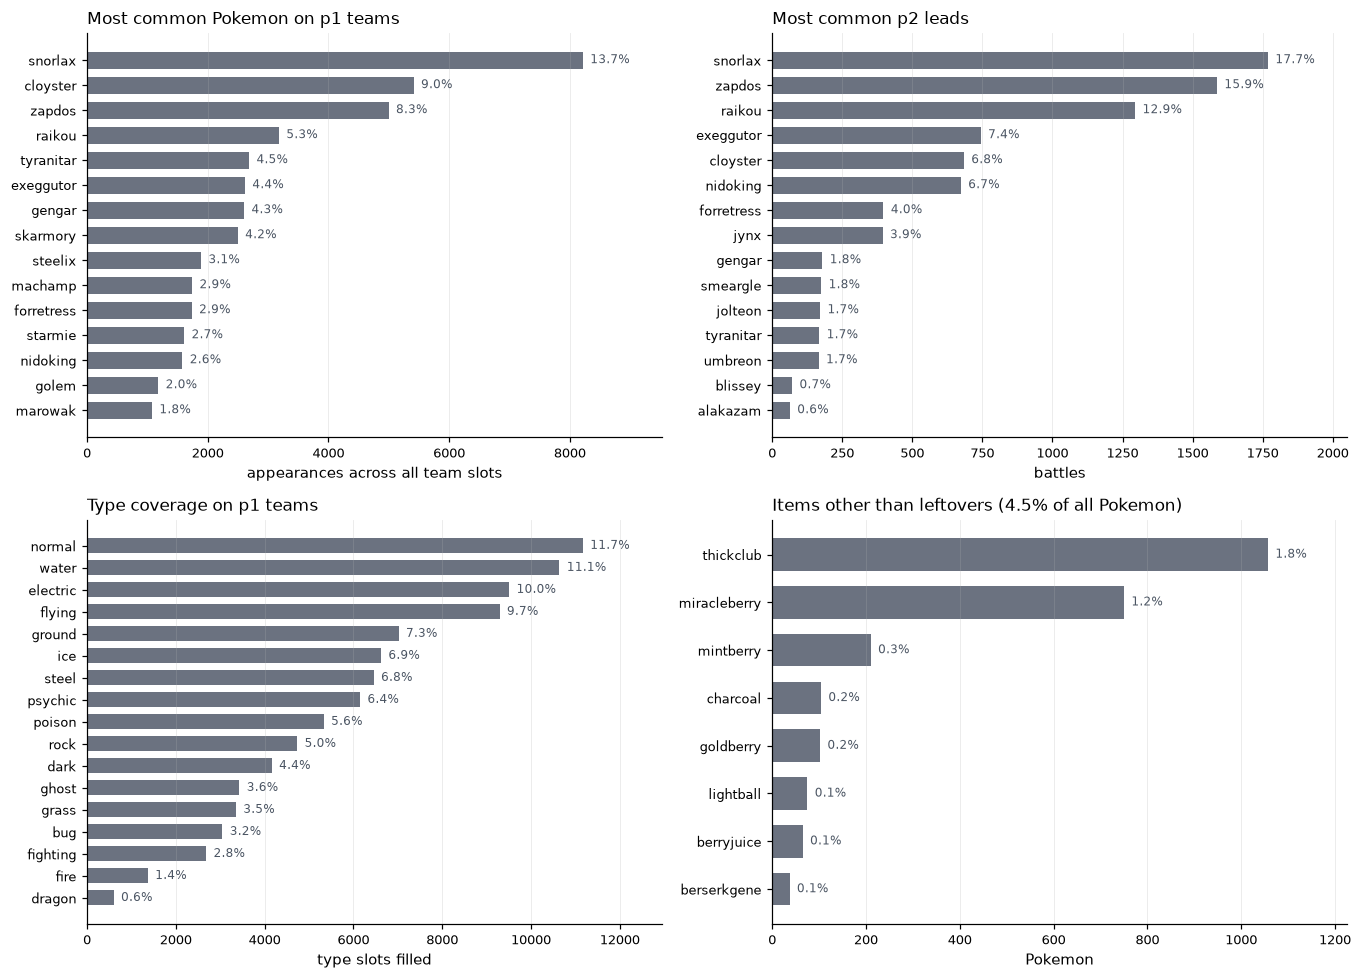

57,329 of 60,000 Pokemon (95.5%) hold leftovers.


In [4]:
p1_species = Counter(p["name"] for b in train_data for p in b["p1_team_details"])
p2_leads = Counter(b["p2_lead_details"]["name"] for b in train_data)
p1_types = Counter(t for b in train_data for p in b["p1_team_details"]
                   for t in p["types"] if t != "notype")
p1_items = Counter(p.get("item", "(none)") for b in train_data for p in b["p1_team_details"])

print(f"distinct species on p1 teams: {len(p1_species)}")
print(f"distinct species as p2 lead:  {len(p2_leads)}")
print(f"distinct real types:          {len(p1_types)}")
print(f"distinct items:               {len(p1_items)}")

levels = Counter(p["level"] for b in train_data for p in b["p1_team_details"])
off_level = sum(count for lvl, count in levels.items() if lvl != 100)
print(f"\nPokemon not at level 100:     {off_level:,} of {sum(levels.values()):,} "
      f"({100 * off_level / sum(levels.values()):.2f}%)")


def barh_top(ax, counter, n, title, xlabel, colour=C_NEUTRAL, denom=None):
    items = counter.most_common(n)[::-1]
    labels = [k for k, _ in items]
    values = [v for _, v in items]
    ax.barh(labels, values, color=colour, height=0.68)
    total = denom if denom is not None else sum(counter.values())
    pad = max(values) * 0.015
    for y, value in enumerate(values):
        ax.text(value + pad, y, f"{100 * value / total:.1f}%",
                va="center", fontsize=8, color="#4B5563")
    ax.set_xlim(0, max(values) * 1.16)
    ax.set_xlabel(xlabel)
    ax.set_title(title, loc="left")
    ax.xaxis.grid(True); ax.yaxis.grid(False)


#convergence: how many different types of pokemon the 6 pokemons span between them.
# E.g. all 6 are water type, convergence = 1.  3 water, 2 fire, 1 grass, convergence = 3.

fig, axes = plt.subplots(2, 2, figsize=(12.5, 9))
barh_top(axes[0, 0], p1_species, 15, "Most common Pokemon on p1 teams",
         "appearances across all team slots")
barh_top(axes[0, 1], p2_leads, 15, "Most common p2 leads", "battles")
barh_top(axes[1, 0], p1_types, 17, "Type coverage on p1 teams",
         "type slots filled")

# pokemons can carry leftovers with them in the battle, which make them recover a bit each turn.
# or they decide to carry something else. 
# most carry leftovers, so we chart the remainder.

n_slots = sum(p1_items.values())
n_leftovers = p1_items.get("leftovers", 0)
rest = Counter({k: v for k, v in p1_items.items() if k != "leftovers"})
barh_top(axes[1, 1], rest, 8,
         f"Items other than leftovers "
         f"({100 * (n_slots - n_leftovers) / n_slots:.1f}% of all Pokemon)",
         "Pokemon", denom=n_slots)
fig.tight_layout()
plt.show()

print(f"{n_leftovers:,} of {n_slots:,} Pokemon ({100 * n_leftovers / n_slots:.1f}%) "
      "hold leftovers.")


# Features

In [5]:
from features_static import build_static
from features_timeline import build_timeline
from features_effects import build_effects
from features_roster import build_roster
from pokedex import build_pokedex
from features_flow import build_flow
from features_matchup import build_matchup
from features_speed import build_speed
from features_damage import build_damage
from features_hazards import build_hazards
from features_moves import build_moves


SEED = 42
CHART_PATH = DATA_DIR / "type_chart_gen2.csv"

# Species -> types and base stats, learned from TRAINING only
DEX = build_pokedex(train_data) #building a species dictionary from the training data, which includes types and base stats for each species. This is important because it allows the model to understand the characteristics of each species without relying on external data.
print(f"pokedex: {len(DEX)} species")


def build_features(data, labelled):
    return (build_static(data, labelled=labelled)
            .merge(build_timeline(data), on="battle_id")
            .merge(build_effects(data), on="battle_id")      
            .merge(build_roster(data), on="battle_id")
            .merge(build_flow(data), on="battle_id")
            .merge(build_matchup(data, CHART_PATH, DEX), on="battle_id")
            .merge(build_speed(data, DEX), on="battle_id")
            .merge(build_damage(data, CHART_PATH, DEX), on="battle_id")
            .merge(build_hazards(data), on="battle_id")
            .merge(build_moves(data), on="battle_id"))


train = build_features(train_data, labelled=True)
test  = build_features(test_data,  labelled=False)

features = [c for c in train.columns if c not in ("battle_id", "player_won")]
X_train, y_train = train[features], train["player_won"]
X_test = test[features]
print(f"{len(features)} features")  



pokedex: 239 species
274 features


# Features

274 features per battle, from 11 modules. The reference set 106 describe the position
each side is in at turn 30. The 168 candidate group describe how it got there and
what is owed in the hidden turns after turn 30.

player 1's six Pokemon are fully described, player 2 shows only its
starting Pokemon, and we see the first 30 turns of a battle that runs to somewhere
between 30 and 80. We are never told how long the battle lasts, and the target is
the final result - not who is ahead at turn 30.

---

## Part 1 - reference set (106 features)

### from build_static - before the fight starts (37)

* **p1** (17): six Pokemon 
    - 2 summaries over stat: mean and max (6*2=12)
    - 2 levels (mean, min)
    - shape (types: how many elements the team covers, dual_type: how many creatures have two types instead of one, special_item: how many carry something other than the defaut item) -3

* **p2** (8): only the opening Pokemon is known, so no averaging is possible
  - its 6 base stats (6), 
  - its level, how many types it has (2)

* **comparisons** (12): p1's mean and max minus p2's opener, for each stat (6*2)

### from build_timeline - what happened in the 30 turns (35)

each of the 30 turns stores 4 things per side: active creatures, HP percentage of the active creature, its status condition, and which move it used. Each of the following appears twice,
once per side:

  - **faints**: how many distinct Pokemon died (2)
  - **health**: mean, final, minimum health of the active Pokemon (6)
  - **health over time**: mean in turns 1-10, mean in turns 21-30, and the change
    between them (6)
  - **status**: share of turns under any ailment, share asleep (4)
  - **loss of control**: how often they swapped Pokemon, how many different ones
    appeared, share of turns where no move happened at all (6)
  - **move quality**: mean power, mean accuracy, share of non-damaging moves (6)
  - **differences**: 5 selected comparisons between the sides (5)

Health here is the *active* Pokemon's, not the team's - it jumps around as Pokemon
switch in and out.

### from build_effects - stat boosts (13)

Boosts are temporary stat increases from moves like Swords Dance, recorded as
"stages" from -6 to +6. 
we get each of the following twice (one per team):
- overall boost level: boost_mean (average total stages per turn),
  boost_max (highest total reached), boost_final (total at turn 30) (6)
- boosts by kind: boost_offensive_mean (atk+spa), boost_defensive_mean
  (def+spd), boost_speed_mean (spe) (6)
- difference: diff_boost_mean (1)

### from features_roster - team material (21)

Fixes a real blind spot: every health column above describes the one Pokemon on
the field. Two sides can both have a healthy Pokemon out while one has five
untouched teammates waiting and the other has five nearly dead. We replay the 30
turns keeping a running note of the last health we saw for every Pokemon, then
snapshot at turns 10, 20 and 30:

  - how many are alive per side, and the difference (3 per checkpoint)
  - total health of the whole team per side, and the difference (3 per checkpoint)
  - plus how fast each side is bleeding: team health at turn 10 minus turn 30 (3)

Pokemon never seen are assumed alive at full health - for p1 that is safe, and we
apply it to p2 as well so the two numbers stay comparable.

---

## Part 2 - candidate group (168 features)

### from build_effects - the effect columns (24)

These were being computed and then silently discarded; the merge kept only columns
with "boost" in the name. "Effects" are ongoing conditions a move left behind:
`substitute` (spent own health to make a decoy that absorbs hits), `trapped`
(cannot switch out), `leechseed` (drains health every turn and gives it to the
opponent), `confusion`, `protect`, `perish`, `attract`, `encore`, `destinybond`,
`clamp`. Per side: the share of the 30 turns each was active (10), plus a share
for *any* effect being active (1). Two differences.

### from features_flow - damage actually dealt and healed (19)

**The gap**: every health column so far is a *level*. None is a *flow*. That
matters because a Pokemon that dies is replaced by a fresh one at full health,
which resets the visible number. A side that knocked out three opponents and a
side that never landed a hit can look identical at turn 30.

We walk the turns tracking each Pokemon's last known health. Its change since we
last saw it is either damage taken (down) or healing (up). Per side (7 each):
total damage taken, total healed, the net, damage taken in turns 1-10, damage
taken in turns 21-30, the single worst hit, and how many turns had a drop over 30%.
Plus 5 comparisons, including a *share* (0.5 means a dead-even trade regardless of
how violent the battle was) and an integral that rewards being ahead for longer
rather than just by more at the end.

### from features_matchup - type effectiveness of the moves used (18)

**The gap**: each move has a `type` field and we were never reading it. Types have
advantages over each other: a Water attack does double damage to a Fire Pokemon,
and some combinations do *nothing at all*. So an identical move can be devastating
or completely wasted depending on what it hits, and the reference set could not tell
the difference.

Defending types come from a species lookup built from the training rosters;
multipliers come from the type chart the organisers supplied. Per side, over the
turns it attacked (7 each): average multiplier achieved, share of attacks hitting
for 2x or more, share hitting a resistance, share hitting a total immunity (a
wasted turn), average multiplier in the last 10 turns, share of attacks matching
the attacker's own type (which gets a 1.5x bonus), and the number of attacking
turns. Plus 4 differences.

### from features_speed - who moves first (8)

**The gap**: speed decides turn order, and turn order decides who lands the
killing blow first. We only had the team's *average* speed and the opening
opponent's - nothing about whether the Pokemon on the field was faster than the
one facing it, turn after turn. Three things change effective speed and all three
are in the data: stat-stage boosts, paralysis (quarters speed in this generation),
and level.

Average effective speed of the active Pokemon per side (2), the average gap, the
share of turns p1 was faster, that same share over the last 10 turns, the share of
exact ties (resolved by coin flip, so a high rate means an unpredictable battle),
and each side's rate of using priority moves - which go first regardless of speed.

### from features_damage - estimated damage per turn (11)

The densest feature here: it folds base stats, level, types, stat boosts, burn,
move power and move accuracy into **one number per turn** - roughly how hard that
attack should have hit.

`power x accuracy x type effectiveness x same-type bonus x (attack / defence)`

Accuracy is included because expected damage matters more than best case. It omits
the real formula's random spread and critical hits, and it does not need to be
right in absolute terms - only to order turns correctly by how much damage they
probably did. Per side (4 each): total, mean, max, and mean over the last 10 turns.
Plus total difference, late difference, and a scale-free share.

### from features_hazards - damage already owed but not yet paid (46)

**The gap, and the reasoning that produced this group**: the four groups above all
describe the *present*, and the reference set already measures the present as team health
and alive counts. Measuring the cause after you have already measured its effect
adds nothing - which is what the ablation found. These columns describe the *future*
instead: commitments made in the visible 30 turns whose cost falls entirely in the
50 hidden turns we predict into. None leaves a mark on turn-30 health.

  - **Spikes** - laid once, it damages every opposing Pokemon that switches in, for
    the rest of the battle. At turn 30 the opponent may look untouched; the debt is
    real. Per side: whether it was laid, on which turn, how many turns it has been
    up, and how many times the opponent has switched since (4 each).
  - **Status, split by severity** - the reference set has one `status_rate`, which averages
    together conditions with wildly different costs over a long battle. Separate rates
    for paralysis, burn, poison, bad poison and freeze (5 each). Bad poison escalates:
    a Pokemon at 80% health is dead within about ten hidden turns.
  - **`doomed`** - the key column. How many of a side's own Pokemon are currently
    *alive* but under escalating damage. Those are health the turn-30 features count
    as an asset and that will be gone before the battle ends.
  - **Move counts** (8 each) and **recovery rate** - whether a side has the healing
    moves to service that debt.
  - Plus `n_species_toxed`, `tox_at_end`, and 4 differences.

### from features_moves - what the moves mean (42)

Chosen after reading the actual move frequencies in the training data. Each column
here **corrects a baseline column that the data shows is wrong**.

  - **Sleep economics** - `rest` appears 23,664 times and `sleeptalk` 20,236. Together
    they are the standard set in this format: heal to full and fall asleep on purpose,
    then keep attacking while asleep. So the reference's `slp_rate` was measuring "runs
    the normal set" and "is crippled" as the same number. `slp_acted_rate` (of the turns
    spent asleep, how many did this side still act on), `slp_dead_rate`, `slp_turns` and
    a `resttalk` flag separate the two.
  - **`explosion`** (5,483 uses) - an intentional death traded for enormous damage.
    The reference's `faints` scores it the same as losing a Pokemon for nothing, which
    is backwards.
  - **`healbell`** (2,229) - cures the whole team's status, cancelling exactly the debt
    the hazards group measures. So `doomed` overstates the damage owed by a side
    carrying it.
  - **`batonpass`** (3,280) - passes stat boosts to a teammate, so boosts can survive a
    switch. The boost columns assume they die with the active Pokemon.
  - **Paralysis moves** (8,552 combined) - quarter the opponent's speed for the rest of
    the battle, which is why measuring speed without them was incomplete.
  - **Trapping plus perish song** - wins outright regardless of health: the opponent
    cannot switch and runs out of turns.
  - 12 move-group counts and 7 derived columns per side, plus 4 differences.

Note this is deliberately **not** a one-hot encoding of all 230 move names - that was
tried on this dataset separately and only reached parity. These are fifteen semantic
flags instead.

---

### GRAND TOTAL: 274 features (the starter notebook had 6)






### Leackage check

In [6]:
# Leakage check: can the battle_id alone predict the winner?
# It shouldn't - an id is just a row label. If it could, the battles were ordered
# in some way that gives the answer away.
# Two ways to look: one correlation over all rows, and the win rate inside a
# sliding window, which would catch drift that a single correlation averages out.

print("no leakage if: correlation within +/-0.03  AND  every stretch in 0.43-0.57\n")
print("corr(battle_id, outcome):", round(train["battle_id"].corr(train["player_won"]), 4))
roll = train.sort_values("battle_id")["player_won"].rolling(500).mean()
print("p1 win rate in any 500 consecutive battles:", round(roll.min(), 3), "/", round(roll.max(), 3))

no leakage if: correlation within +/-0.03  AND  every stretch in 0.43-0.57

corr(battle_id, outcome): 0.0094
p1 win rate in any 500 consecutive battles: 0.45 / 0.548


### Feature matrix checks

In [7]:
#every model after this point is trained on the features,
# and there might be three kinds of problems thatcause failures that are hard to
# diagnose later - an infinity makes a linear model produce nonsense
# coefficients without complaining, a column that is the same value in every
# battle silently wastes a slot, and NaNs behave differently depending on which
# model sees them.


Xf = train[features]

nan_counts = Xf.isna().sum()
# np.isinf needs a float array; this also catches infinities hiding in columns
# pandas is storing as integers.
inf_counts = pd.Series(
    {c: int(np.isinf(Xf[c].to_numpy(dtype="float64")).sum()) for c in features})
# nunique(dropna=False) counts NaN as its own value, so a column that is all
# NaN registers as constant rather than slipping through as "1 distinct value".
constant = [c for c in features if Xf[c].nunique(dropna=False) <= 1]

n_nan = int(nan_counts.sum())
print(f"features:           {len(features)}")
print(f"columns with NaN:   {int((nan_counts > 0).sum())}  ({n_nan:,} cells, "
      f"{100*n_nan/Xf.size:.2f}% of the table)")
print(f"columns with inf:   {int((inf_counts > 0).sum())}")
print(f"constant columns:   {len(constant)}{' -> ' + str(constant) if constant else ''}")



features:           274
columns with NaN:   20  (939 cells, 0.03% of the table)
columns with inf:   0
constant columns:   0


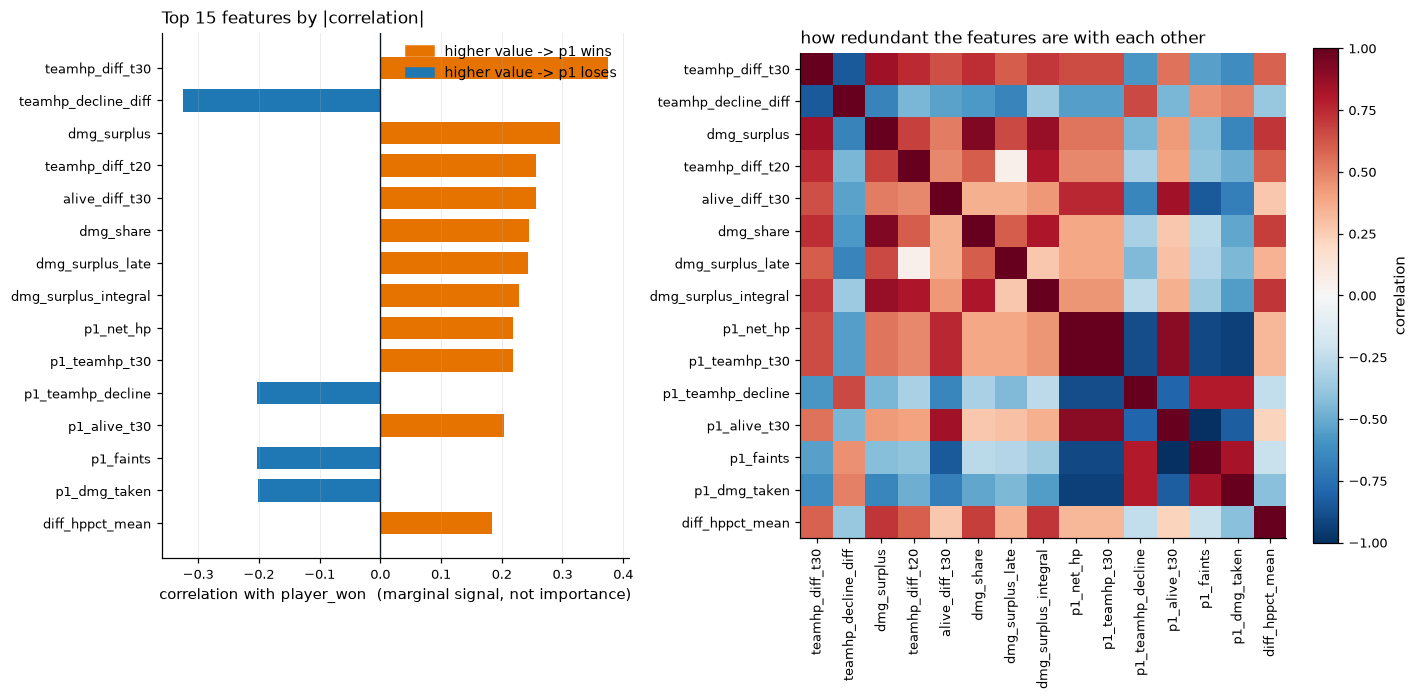

In [8]:
#which single features carry signal, and how much they overlap

#Left:  each feature's correlation with the outcome, on its own.
# Right: how strongly those same features correlate with each other.

# the features with the most individual signal are also largely measuring 
# the same thing. That is the evidence behind two later decisions:
# keeping all 274 columns, and reporting group-level ablation rather than 
# per-feature importances.

# note: a feature can correlate near zero and still matter in combination 
# with others.

# corrwith gives each column's correlation against the target. dropna() removes
# any constant column. 
usable = [c for c in features if c not in constant]

signal = (Xf[usable].corrwith(train["player_won"]).dropna()
          .sort_values(key=lambda s: s.abs(), ascending=False))

# 15 rather than 20: several feature names are long, and at 20 rows the rotated
# tick labels on the heatmap become unreadable.
TOP_N = 15
# [::-1] reverses the order so that barh - which draws its first row at the
# bottom - ends up with the strongest feature at the top.
top = signal.head(TOP_N)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 6.4),
                         gridspec_kw={"width_ratios": [1, 1.15]})

#signed correlation with the target 
ax = axes[0]
# Colour by direction, not magnitude: orange where a higher value goes with p1
# winning, blue where it goes with losing. Matches the palette used elsewhere.
ax.barh(top.index, top.values,
        color=[C_WIN if v > 0 else C_LOSE for v in top.values], height=0.7)
ax.axvline(0, color="#111827", linewidth=0.9)
ax.set_xlabel("correlation with player_won  (marginal signal, not importance)")
ax.set_title(f"Top {TOP_N} features by |correlation|", loc="left")
ax.xaxis.grid(True); ax.yaxis.grid(False)

handles = [plt.Rectangle((0, 0), 1, 1, color=C_WIN),
           plt.Rectangle((0, 0), 1, 1, color=C_LOSE)]
ax.legend(handles, ["higher value -> p1 wins", "higher value -> p1 loses"],
          loc="upper right")

# how much those features overlap each other 
ax = axes[1]
# not reversed here, and that is deliberate: imshow draws row 0 at the top, so
# this puts the strongest feature top-left and matches the bar chart's order.
order = signal.head(TOP_N).index.tolist()
sub = Xf[order].corr().to_numpy()
# Diverging scale: two hues with a neutral middle, centred on zero, because the
# sign of a correlation is the thing we care about. vmin/vmax pinned to -1/+1 so
# the colours mean the same thing regardless of what this particular subset
# happens to contain.
im = ax.imshow(sub, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(order)), order, rotation=90)
ax.set_yticks(range(len(order)), order)
ax.set_title("how redundant the features are with each other", loc="left")
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.046, label="correlation")

fig.tight_layout()
plt.show()


### Which features actually help

In [9]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import RepeatedStratifiedKFold

#record of which module produced which column, and we need that to test modules one at a time.

_static   = build_static(train_data, labelled=True)
_timeline = build_timeline(train_data)
_effects  = build_effects(train_data)
_roster   = build_roster(train_data)

def cols(frame, keep=None):

    #Column names of a feature frame, minus the id and the target.
    
    out = [c for c in frame.columns if c not in ("battle_id", "player_won")]
    return [c for c in out if keep(c)] if keep else out

# Comparing the reference set (baseline) with each candidate group. 
# Note the effects module contributes ONLY its boost columns here - its
# effect-rate columns are a candidate group, tested separately.

BASELINE = (cols(_static) + cols(_timeline) + cols(_roster)
            + cols(_effects, lambda c: "boost" in c))

#candidate groups: each module's columns, minus the baseline columns.  
# The effects module contributes only its effect-rate columns here, 
# since its boost columns are already in the baseline.
GROUPS = {
    "eff_rates": cols(_effects, lambda c: "eff_" in c),
    "flow":      cols(build_flow(train_data)),
    "matchup":   cols(build_matchup(train_data, CHART_PATH, DEX)),
    "speed":     cols(build_speed(train_data, DEX)),
    "damage":    cols(build_damage(train_data, CHART_PATH, DEX)),
    "hazards":   cols(build_hazards(train_data)),
    "moves":     cols(build_moves(train_data)),
}
print(f"baseline {len(BASELINE)} cols | "
      + " | ".join(f"{k} {len(v)}" for k, v in GROUPS.items()))


# 10 fixed train/test splits (5-fold, done twice with different shuffles).
# Stratified = each fold keeps the ~50/50 win balance. random_state = same
# splits on every run.

sweep_cv = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42)
                .split(X_train, y_train))

# Two models from different families, because a feature group can help one kind
# of model and not the other - a tree can use thresholds and interactions that
# a linear model cannot represent at all.

MODELS = {

    # Logistic regression needs numbers on a comparable scale and cannot accept
    # NaN, hence the imputer + scaler pipeline wrapped around it.

    "LR C=0.1": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                              LogisticRegression(C=0.1, max_iter=4000, random_state=SEED)),

    # The tree needs no scaling, and HistGradientBoosting handles NaN natively,
    # so it takes the raw columns. early_stopping=False keeps it deterministic:
    # with it on, the model would carve out its own random validation slice.

    "HGB": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.06,
                                          max_leaf_nodes=15, min_samples_leaf=40,
                                          l2_regularization=5.0, early_stopping=False,
                                          random_state=SEED),
}

rows = []
for model_name, model in MODELS.items():


    base = cross_val_score(model, X_train[BASELINE], y_train,
                           cv=sweep_cv, n_jobs=-1)
    rows.append({"model": model_name, "group": "(baseline)",
                 "n_cols": len(BASELINE), "accuracy": base.mean(),
                 "delta_pp": 0.0, "se_pp": 0.0})
    for group_name, group_cols in GROUPS.items():
        with_group = cross_val_score(model, X_train[BASELINE + group_cols], y_train,
                                     cv=sweep_cv, n_jobs=-1)
        paired = (with_group - base) * 100          # per-fold difference
        rows.append({"model": model_name, "group": group_name,
                     "n_cols": len(group_cols), "accuracy": with_group.mean(),
                     "delta_pp": paired.mean(),
                     "se_pp": paired.std(ddof=1) / np.sqrt(len(paired))})

ablation = pd.DataFrame(rows)

# The decision rule: a group is only accepted if its gain is more than TWICE
# its own standard error, i.e. clearly bigger than the measurement's own
# uncertainty. "noise" is the honest third verdict - the effect is either zero
# or too small for 10,000 battles to resolve, and we cannot tell which. Without
# this rule we would keep every group that happened to score above zero, which
# on these sample sizes is close to keeping coin flips.

ablation["keep?"] = np.where(ablation["delta_pp"] > 2 * ablation["se_pp"], "yes",
                    np.where(ablation["delta_pp"] < -2 * ablation["se_pp"], "no", "noise"))
display(ablation.round(4))

baseline 106 cols | eff_rates 24 | flow 19 | matchup 18 | speed 8 | damage 11 | hazards 46 | moves 42


,model,group,n_cols,accuracy,delta_pp,se_pp,keep?
0,LR C=0.1,(baseline),106,0.6675,0.000,0.0000,noise
1,LR C=0.1,eff_rates,24,0.6666,-0.090,0.0640,noise
2,LR C=0.1,flow,19,0.6676,0.010,0.1903,noise
3,LR C=0.1,matchup,18,0.6661,-0.140,0.1038,noise
4,LR C=0.1,speed,8,0.6663,-0.120,0.1482,noise
5,LR C=0.1,damage,11,0.6694,0.195,0.1963,noise
6,LR C=0.1,hazards,46,0.6690,0.155,0.1852,noise
7,LR C=0.1,moves,42,0.6672,-0.025,0.1268,noise
8,HGB,(baseline),106,0.6643,0.000,0.0000,noise
9,HGB,eff_rates,24,0.6620,-0.225,0.1767,noise


The cell below, tries 4 different bundles of measurements and reports which bundle predicts best.

In [10]:
# The ablation above adds exactly one group to the reference set, so it can
# never show what several groups do in combination - and groups can interact,
# or overlap and make each other redundant. These four sets answer that.
#   baseline   - the reference set alone, for comparison
#   keep3      - baseline plusthe three groups that scored positive on the tree (matchup, damage, hazards)
#   keep4      - keep3 plus moves
#   everything - all seven groups, including the ones that scored as noise

candidate_sets = {
    "baseline":   BASELINE,
    "keep3":      BASELINE + GROUPS["matchup"] + GROUPS["damage"] + GROUPS["hazards"],
    "keep4":      BASELINE + GROUPS["matchup"] + GROUPS["damage"] + GROUPS["hazards"] + GROUPS["moves"],
    "everything": BASELINE + sum(GROUPS.values(), []),
}

# `ref` stores each model's per-fold baseline scores, so every other set can be
# compared against its OWN model's baseline rather than across models.
rows, ref = [], {}
for model_name, model in MODELS.items():
    for set_name, c in candidate_sets.items():
        # Same fixed folds as the ablation cell, so these numbers are directly
        # comparable with the ones above.
        s = cross_val_score(model, X_train[c], y_train, cv=sweep_cv, n_jobs=-1)
        if set_name == "baseline":
            ref[model_name] = s
        d = (s - ref[model_name]) * 100
        rows.append({"model": model_name, "set": set_name, "n_cols": len(c),
                     "accuracy": s.mean(), "delta_pp": d.mean(),
                     "se_pp": d.std(ddof=1) / np.sqrt(len(d))})
sets_table = pd.DataFrame(rows)
display(sets_table.round(4))
# Pick the highest-scoring row and keep its COLUMN SET as the feature set used
# from here on. This chooses features only, the model is chosen later.
# Caveat worth knowing: this is the maximum of 8 numbers all measured on the

best = sets_table.loc[sets_table["accuracy"].idxmax()]
FINAL_COLS = candidate_sets[best["set"]]
print(f"\nbest: {best['model']} on '{best['set']}' = {best['accuracy']:.4f} "
      f"({len(FINAL_COLS)} cols)")

,model,set,n_cols,accuracy,delta_pp,se_pp
0,LR C=0.1,baseline,106,0.6675,0.000,0.0000
1,LR C=0.1,keep3,181,0.6758,0.830,0.2613
2,LR C=0.1,keep4,223,0.6754,0.790,0.3478
3,LR C=0.1,everything,274,0.6785,1.100,0.3477
4,HGB,baseline,106,0.6643,0.000,0.0000
5,HGB,keep3,181,0.6720,0.775,0.2055
6,HGB,keep4,223,0.6731,0.875,0.2177
7,HGB,everything,274,0.6731,0.880,0.3089



best: LR C=0.1 on 'everything' = 0.6785 (274 cols)


# Models

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (GradientBoostingClassifier, RandomForestClassifier,
                              ExtraTreesClassifier, HistGradientBoostingClassifier)
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import LinearSVC

# The cells above settled which features to use. This one asks a different
# question: linear, tree-based, or distance-based? 

SEED = 42

cv_scheme = RepeatedStratifiedKFold(n_splits=5, n_repeats=6, random_state=0)


def scaled(estimator):
    #Impute, then scale. 
    # Linear models and anything measuring distance cannot take
    # NaN, and without scaling a stat in the hundreds would swamp a rate
    # between 0 and 1 purely because of its units.
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), estimator)


def bare(estimator):
    #Impute only. Trees need no scaling but still reject NaN.
    # HistGradientBoosting below is the exception - it handles NaN itself and
    # so takes neither wrapper.
    return make_pipeline(SimpleImputer(strategy="median"), estimator)


candidates = {
    "Logistic Regression C=1":    scaled(LogisticRegression(C=1.0,  max_iter=4000, random_state=SEED)),
    "Logistic Regression C=0.1":  scaled(LogisticRegression(C=0.1,  max_iter=4000, random_state=SEED)),
    "Logistic Regression C=0.01": scaled(LogisticRegression(C=0.01, max_iter=4000, random_state=SEED)),
    "Linear Discriminant":        scaled(LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")),
    "Linear SVC":                 scaled(LinearSVC(C=0.01, max_iter=5000, random_state=SEED)),
    #"Gradient Boosting":          bare(GradientBoostingClassifier(random_state=SEED)),
    "Hist Gradient Boosting":     HistGradientBoostingClassifier(
                                      max_iter=200, learning_rate=0.06,
                                      max_leaf_nodes=15, min_samples_leaf=40,
                                      l2_regularization=5.0, early_stopping=False,
                                      random_state=SEED),
    "Random Forest":              bare(RandomForestClassifier(n_estimators=400, min_samples_leaf=5, random_state=SEED)),
    "Extra Trees":                bare(ExtraTreesClassifier(n_estimators=400, min_samples_leaf=5, random_state=SEED)),
    #"k-Nearest Neighbours":       scaled(KNeighborsClassifier(n_neighbors=50)),
    #"Decision Tree":              bare(DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=SEED)),
}

#removing decision tree from candidates because it is not performing well and we want to focus on the other models.
#removing gradient boosting from candidates because it is not performing as well as other models and it takes a long time to train.
#removing k-nearest neighbours from candidates because it is not performing as well.

results = {}
for name, candidate in candidates.items():
    scores = cross_val_score(candidate, X_train, y_train, cv=cv_scheme, n_jobs=-1)
    results[name] = scores

comparison = (pd.DataFrame({k: [v.mean(), v.std()] for k, v in results.items()},
                           index=["mean_accuracy", "std"]).T
              .sort_values("mean_accuracy", ascending=False))
display(comparison)

# This is not the final model. It is the best single model, printed
# to record which family and which regularisation setting won.
best_name = comparison.index[0]
print(f"Best model: {best_name} (CV {comparison.loc[best_name, 'mean_accuracy']:.4f})")


,mean_accuracy,std
Logistic Regression C=0.01,0.677717,0.008868
Linear Discriminant,0.676517,0.008900
Logistic Regression C=1,0.675767,0.009750
Logistic Regression C=0.1,0.675750,0.009598
Linear SVC,0.675050,0.009619
Hist Gradient Boosting,0.673800,0.009516
Extra Trees,0.668900,0.011057
Random Forest,0.667117,0.012031


Best model: Logistic Regression C=0.01 (CV 0.6777)


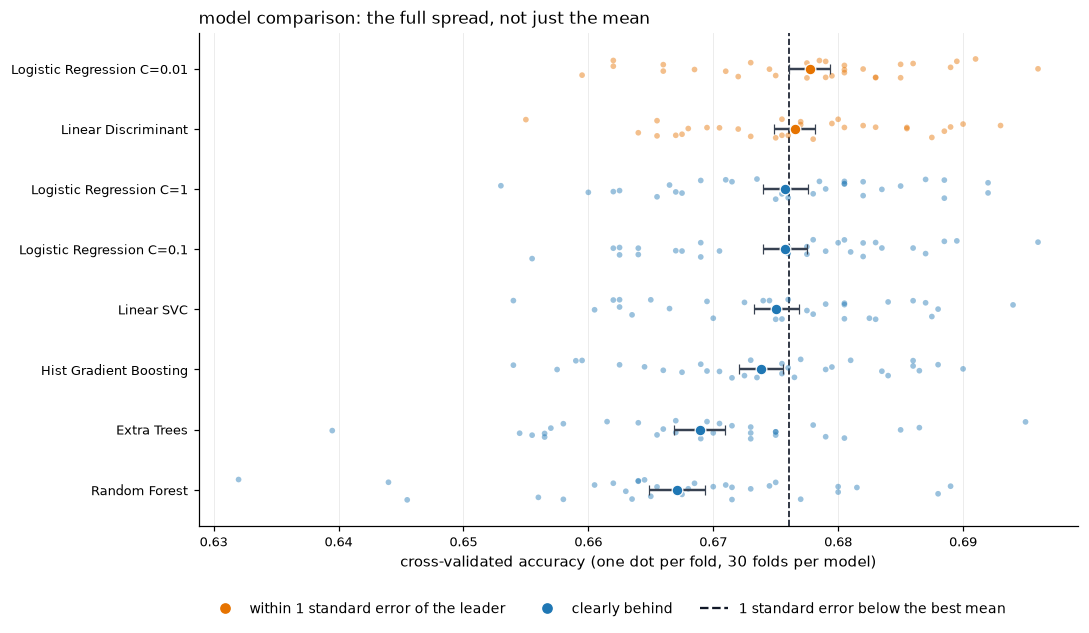

,mean,std,std_error,min,max,vs_best_pp,vs_best_se
Logistic Regression C=0.01,0.6777,0.0090,0.0016,0.6595,0.696,0.0000,0.0000
Linear Discriminant,0.6765,0.0091,0.0017,0.6550,0.693,-0.1200,0.0588
Logistic Regression C=1,0.6758,0.0099,0.0018,0.6530,0.692,-0.1950,0.0747
Logistic Regression C=0.1,0.6758,0.0098,0.0018,0.6555,0.696,-0.1967,0.0622
Linear SVC,0.6750,0.0098,0.0018,0.6540,0.694,-0.2667,0.0616
Hist Gradient Boosting,0.6738,0.0097,0.0018,0.6540,0.690,-0.3917,0.1757
Extra Trees,0.6689,0.0112,0.0021,0.6395,0.695,-0.8817,0.1500
Random Forest,0.6671,0.0122,0.0022,0.6320,0.689,-1.0600,0.1739


statistically hard to separate from Logistic Regression C=0.01: ['Logistic Regression C=0.01']


In [12]:

# this is what told us there was no single best model, which is why the final
# submission combines two of them instead of picking one.

spread = pd.DataFrame(results)                     # 30 fold scores x 8 models
order = spread.mean().sort_values().index          # worst at the bottom
means = spread.mean()
errors = spread.std() / np.sqrt(len(spread))       # standard error of the mean
# a rough visual guide: one standard error below the best average. 
cutoff = means.max() - errors[means.idxmax()]

fig, ax = plt.subplots(figsize=(10, 0.56 * len(order) + 1.8))
rng = np.random.default_rng(0)           # fixed seed so the jitter never changes
for y, name in enumerate(order):
    scores = spread[name].to_numpy()
    # every individual fold score, jittered up and down a little so that
    # overlapping points stay visible. 
    inside = means[name] >= cutoff
    colour = C_WIN if inside else C_LOSE
    ax.scatter(scores, y + rng.uniform(-0.17, 0.17, len(scores)), s=14,
               color=colour, alpha=0.45, edgecolors="none", zorder=2)
    
    ax.errorbar(means[name], y, xerr=errors[name], fmt="o", markersize=7,
                color=colour, ecolor="#374151", elinewidth=1.6, capsize=3,
                markeredgecolor="white", markeredgewidth=0.8, zorder=3)

ax.axvline(cutoff, color="#111827", linestyle="--", linewidth=1.1, zorder=1)
ax.set_yticks(range(len(order)), order)
ax.set_ylim(-0.6, len(order) - 0.4)
ax.set_xlabel("cross-validated accuracy (one dot per fold, 30 folds per model)")
ax.set_title("model comparison: the full spread, not just the mean", loc="left")
ax.xaxis.grid(True); ax.yaxis.grid(False)
handles = [plt.Line2D([], [], marker="o", linestyle="", color=C_WIN),
           plt.Line2D([], [], marker="o", linestyle="", color=C_LOSE),
           plt.Line2D([], [], linestyle="--", color="#111827")]

ax.legend(handles, ["within 1 standard error of the leader", "clearly behind",
                    "1 standard error below the best mean"],
          loc="upper left", bbox_to_anchor=(0, -0.13), ncol=3)

fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

#comparing each model against the best one, fold by fold.
# every model was scored on the same folds, so a fold that happens to be
# difficult drags all of them down together. subtracting one model from another
# within each fold cancels that shared difficulty out, and gives a much tighter
# estimate of the gap between two models than comparing their separate error
# bars does. 
leader = means.idxmax()
paired = {name: (spread[name] - spread[leader]) * 100 for name in spread.columns}

summary = (pd.DataFrame({"mean": means, "std": spread.std(), "std_error": errors,
                         "min": spread.min(), "max": spread.max()})
           .sort_values("mean", ascending=False))
summary["vs_best_pp"] = [paired[n].mean() for n in summary.index]
summary["vs_best_se"] = [paired[n].std(ddof=1) / np.sqrt(len(spread))
                         for n in summary.index]
# note on the two spread columns: "std" is how much the score varies between
# folds, while "std_error" is how uncertain the average itself is.
display(summary.round(4))

# a model counts as tied with the leader if the paired gap is smaller than
# twice its own standard error. same threshold we used to decide which feature
# groups to keep. the leader is tied with itself by definition, which is why
# the max() guards against dividing by a standard error of exactly zero.
tied = [n for n in summary.index
        if abs(summary.loc[n, "vs_best_pp"]) < 2 * max(summary.loc[n, "vs_best_se"], 1e-9)]
print(f"statistically hard to separate from {leader}: {tied}")
if len(tied) > 1:
    print("more than one candidate is in range, so the choice can rest on "
          "something other than the average - how stable it is across folds, "
          "how fast it trains, or whether it disagrees usefully with the "
          "others. we took the last of these: the final model averages two of "
          "these candidates from different families, which disagree with each "
          "other on about 14% of battles.")

In [13]:
# HistGradientBoosting builds hundreds of TINY trees in sequence, each one
# correcting the mistakes left by the ones before it. These five settings all
# control how much each little tree is allowed to do:

# max_leaf_nodes:       how many final buckets one tree can split the data into.
#                       2 = a single yes/no question, so the model can only add
#                       up per-feature effects and can never combine two
#                       features. 3 = two questions, so one pairwise
#                       interaction. Higher = more interactions, more capacity
#                       to overfit.

#min_samples_leaf:      the fewest battles a tree is allowed to put in one
#                       group. At 200, every rule the tree makes has to hold
#                       for at least 200 battles, so it cannot invent a rule
#                       that only fits a dozen unusual ones and call it a
#                       pattern. Higher = fewer, broader rules.

#l2_regularization:     a penalty on how strongly any single tree can push the
#                       prediction. Higher means every tree only nudges, so the
#                       model has to reach its answer through many small
#                       corrections that agree with each other, instead of a
#                       few confident trees that might each be wrong.

#learning_rate:         step size, how much of a tree's correction is actually applied.

#max_iter:              how many trees in total. Lower learning_rate needs MORE
#                       trees to reach the same place, which is why the two
#                       move in opposite directions down this list.


deeper = {
    "leaves_4":  dict(max_leaf_nodes=4, min_samples_leaf=150, l2_regularization=20.0,
                      learning_rate=0.03, max_iter=800),
    "leaves_3":  dict(max_leaf_nodes=3, min_samples_leaf=200, l2_regularization=20.0,
                      learning_rate=0.02, max_iter=1500),
    "leaves_2":  dict(max_leaf_nodes=2, min_samples_leaf=200, l2_regularization=20.0,
                      learning_rate=0.02, max_iter=2000),
    "leaves_2_slow": dict(max_leaf_nodes=2, min_samples_leaf=100, l2_regularization=10.0,
                          learning_rate=0.01, max_iter=4000),
    "leaves_3_slow": dict(max_leaf_nodes=3, min_samples_leaf=100, l2_regularization=10.0,
                          learning_rate=0.015, max_iter=3000),
}
# best_acc starts at 0 because accuracy can only go up from there. best_hgb
# ends up holding the winning UNFITTED model, which the ensemble cell(combined LR and HGB)
# will use.
best_hgb, best_acc = None, 0
for name, kw in deeper.items():
    m = HistGradientBoostingClassifier(early_stopping=False, random_state=SEED, **kw)
    s = cross_val_score(m, X_train[FINAL_COLS], y_train, cv=sweep_cv, n_jobs=-1)
    print(f"{name:14s} {s.mean():.4f} +/- {s.std(ddof=1)/np.sqrt(len(s)):.4f}")
    if s.mean() > best_acc:
        best_acc, best_hgb = s.mean(), m
print("\nchosen:", best_hgb.get_params())

leaves_4       0.6780 +/- 0.0016
leaves_3       0.6789 +/- 0.0016
leaves_2       0.6727 +/- 0.0018
leaves_2_slow  0.6728 +/- 0.0016
leaves_3_slow  0.6767 +/- 0.0019

chosen: {'categorical_features': 'from_dtype', 'class_weight': None, 'early_stopping': False, 'interaction_cst': None, 'l2_regularization': 20.0, 'learning_rate': 0.02, 'loss': 'log_loss', 'max_bins': 255, 'max_depth': None, 'max_features': 1.0, 'max_iter': 1500, 'max_leaf_nodes': 3, 'min_samples_leaf': 200, 'monotonic_cst': None, 'n_iter_no_change': 10, 'random_state': 42, 'scoring': 'loss', 'tol': 1e-07, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}


In [14]:
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import cross_val_predict


# The logistic regression needs two things done first, which is what the
# pipeline is for: SimpleImputer fills any missing cell with that column's
# median, and StandardScaler puts every column on a comparable scale so that 
# a stat measured in the hundreds does not drown out a rate between 0 and 1. 
# The tree needs neither, which is why best_hgb is used bare.
# C=0.01 is the regularisation strength, a smaller C means a MORE restrained model. 
# 0.01 is heavily restrained, and on this data it beat C=0.1 and C=1.

lr = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                   LogisticRegression(C=0.01, max_iter=4000, random_state=SEED))


#ensemble (ens) combines the two models (LR and HGB) to test if they can help each other. 
#The two models are different enough that they make different mistakes, 
#so combining them can improve accuracy.

# Both LR and HGB produce a probability that player 1 wins, not just a binary prediction. 
# Voting="soft" averages the two models' probabilities, and predicts 1 if the average is
# above 0.5. 

# The two models get different battles wrong. When their mistakes are independent, 
# averaging cancels some of them out. When they make the same mistakes, averaging 
# changes nothing - which is what the last line of this cell checks.

ens = VotingClassifier([("lr", lr), ("hgb", best_hgb)], voting="soft")

# scored keeps each model's per-fold scores, not just the averages, so the two
# can be compared fold by fold below.

scored = {}
for name, m in [("LR", lr), ("HGB", best_hgb), ("ensemble", ens)]:
    s = cross_val_score(m, X_train[FINAL_COLS], y_train, cv=sweep_cv, n_jobs=-1)
    scored[name] = s
    print(f"{name:9s} {s.mean():.4f} +/- {s.std(ddof=1)/np.sqrt(len(s)):.4f}")

# Compare the ensemble against the better of its two members, fold by fold.

d = (scored["ensemble"] - scored["HGB"]) * 100
print(f"\nensemble vs HGB: {d.mean():+.3f} +/- {d.std(ddof=1)/np.sqrt(len(d)):.3f} pp")

# How often do the two models actually give different answers? 
# cross_val_predict returns one prediction per battle, from a model that never
# saw that battle in training - which requires every battle to appear in
# exactly one test fold. sweep_cv holds two complete 5-fold passes stacked, so
# [:5] takes the first pass only; passing all 10 would predict each battle
# twice and the call would fail.

p_lr  = cross_val_predict(lr,       X_train[FINAL_COLS], y_train, cv=sweep_cv[:5])
p_hgb = cross_val_predict(best_hgb, X_train[FINAL_COLS], y_train, cv=sweep_cv[:5])
print(f"the two models disagree on {(p_lr != p_hgb).mean():.1%} of battles")

LR        0.6780 +/- 0.0029
HGB       0.6789 +/- 0.0016
ensemble  0.6822 +/- 0.0021

ensemble vs HGB: +0.330 +/- 0.188 pp
the two models disagree on 13.8% of battles


In [15]:

FINAL_NAME  = "LR C=0.01 + HGB(3 leaves) soft-vote ensemble"
FINAL_MODEL = ens
FINAL_COLS  = FINAL_COLS          

final_scores = cross_val_score(FINAL_MODEL, X_train[FINAL_COLS], y_train,
                               cv=cv_scheme, n_jobs=-1)
print(f"{FINAL_NAME}\nCV {final_scores.mean():.4f} +/- {final_scores.std():.4f} "
      f"on {len(FINAL_COLS)} features")

# Now fit on all 10,000 battles. Every model scored during
# cross-validation only ever saw 8,000 at a time, so this one is trained on 25%
# more data and should be slightly better than the number printed above.
# X_test[FINAL_COLS] selects the same columns in the same order as training.

FINAL_MODEL.fit(X_train[FINAL_COLS], y_train)
test_predictions = FINAL_MODEL.predict(X_test[FINAL_COLS]) #sanity check
print(f"predicted 'player 1 wins' for {test_predictions.mean():.1%} of test battles")

LR C=0.01 + HGB(3 leaves) soft-vote ensemble
CV 0.6819 +/- 0.0101 on 274 features
predicted 'player 1 wins' for 51.6% of test battles


# Creating the Submission File

The competition requires a `.csv` file with two columns: `battle_id` and `player_won`. Let's use our trained model to make predictions on the test set and format them correctly.

In [16]:
sample_submission = pd.read_csv(sample_submission_path)
expected_columns = ['battle_id', 'player_won']
if list(sample_submission.columns) != expected_columns:
    raise ValueError(f"Expected {expected_columns}, got {list(sample_submission.columns)}")

predictions_by_id = pd.Series(test_predictions, index=test["battle_id"])
submission_df = sample_submission.copy()
submission_df['player_won'] = submission_df['battle_id'].map(predictions_by_id)
if submission_df['player_won'].isna().any():
    raise ValueError("Some battle_id values have no matching prediction.")
submission_df['player_won'] = submission_df['player_won'].astype(int)

submission_df.to_csv(OUTPUT_DIR / 'submission.csv', index=False)

# record what produced this file: model, score, and feature count
best_scores = results[best_name]
(OUTPUT_DIR / "cv_score.txt").write_text(
    f"model: {best_name}\n"
    f"cv accuracy: {best_scores.mean():.4f} +/- {best_scores.std():.4f}\n"
    f"features: {len(features)}\n"
)
print(f"Saved: {OUTPUT_DIR / 'submission.csv'}")

Saved: /Users/emilykokkinofta/Projects/FDS_Challenge_26/outputs/aimilia/274feat_ensemble/submission.csv


# Overfitting and Underfitting test

1. MEMORISATION CHECK
   training accuracy    0.7078   (battles it was fitted on)
   cross-val accuracy   0.6819   (battles it never saw)
   gap                  +2.59 pp
   under ~2pp = well regularised | over ~10pp = memorising

2. UNTOUCHED FOLDS
   folds used for tuning (seed 42)   0.6822
   final-score folds    (seed 0)     0.6819
   never-seen folds     (seed 999)   0.6846
   all three within ~0.3pp = the tuning is not fold-specific



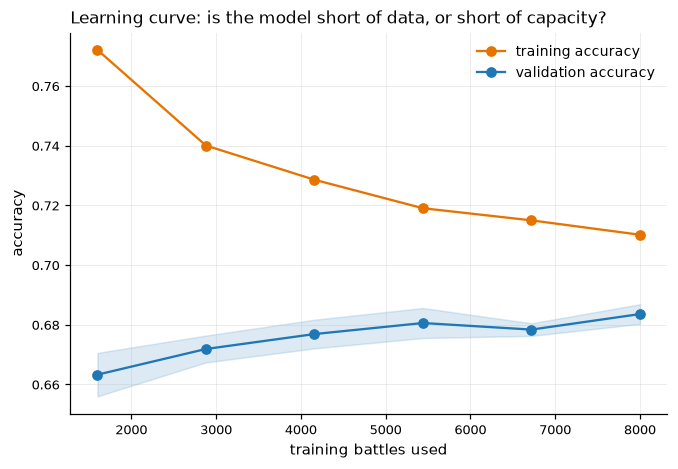

3. LEARNING CURVE
   gap at 20% of the data   +10.88 pp
   gap at 100% of the data  +2.66 pp
   validation gain, last step +0.52 pp


In [17]:
from sklearn.base import clone
from sklearn.model_selection import learning_curve

# does the model memorise? train accuracy vs cross-validated accuracy.
# clone() makes an unfitted copy. FINAL_MODEL has already been fitted and used
# to write the submission, so we leave it alone and experiment on a duplicate.

m = clone(FINAL_MODEL)
m.fit(X_train[FINAL_COLS], y_train)
train_acc = m.score(X_train[FINAL_COLS], y_train)
print("1. MEMORISATION CHECK")
print(f"   training accuracy    {train_acc:.4f}   (battles it was fitted on)")
print(f"   cross-val accuracy   {final_scores.mean():.4f}   (battles it never saw)")
print(f"   gap                  {100*(train_acc - final_scores.mean()):+.2f} pp")
print("   under ~2pp = well regularised | over ~10pp = memorising\n")


# Nothing was tuned against seed 999. If the score holds here, the tuning
# found real structure rather than quirks of the folds used to choose it.
fresh = cross_val_score(FINAL_MODEL, X_train[FINAL_COLS], y_train,
                        cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=2,
                                                   random_state=999),
                        n_jobs=-1)
print("2. UNTOUCHED FOLDS")
print(f"   folds used for tuning (seed 42)   {scored['ensemble'].mean():.4f}")
print(f"   final-score folds    (seed 0)     {final_scores.mean():.4f}")
print(f"   never-seen folds     (seed 999)   {fresh.mean():.4f}")
print("   all three within ~0.3pp = the tuning is not fold-specific\n")

# learning_curve refits the model at six training-set sizes - 20%, 36%, 52%,
# 68%, 84% and 100% of the data - and at each size reports accuracy on the
# battles used for training and on held-out battles. Watching the two curves
# converge or diverge tells us which resource is the binding constraint.


sizes, tr, va = learning_curve(FINAL_MODEL, X_train[FINAL_COLS], y_train,
                               train_sizes=np.linspace(0.2, 1.0, 6),
                               cv=5, n_jobs=-1, shuffle=True, random_state=0)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(sizes, tr.mean(axis=1), "o-", color=C_WIN, label="training accuracy")
ax.plot(sizes, va.mean(axis=1), "o-", color=C_LOSE, label="validation accuracy")
ax.fill_between(sizes, va.mean(axis=1) - va.std(axis=1),
                va.mean(axis=1) + va.std(axis=1), color=C_LOSE, alpha=0.15)
ax.set_xlabel("training battles used")
ax.set_ylabel("accuracy")
ax.set_title("Learning curve: is the model short of data, or short of capacity?", loc="left")
ax.legend()
plt.show()

print("3. LEARNING CURVE")
print(f"   gap at 20% of the data   {100*(tr.mean(axis=1)[0]  - va.mean(axis=1)[0]):+.2f} pp")
print(f"   gap at 100% of the data  {100*(tr.mean(axis=1)[-1] - va.mean(axis=1)[-1]):+.2f} pp")
print(f"   validation gain, last step {100*(va.mean(axis=1)[-1] - va.mean(axis=1)[-2]):+.2f} pp")